# LightGBM tuning, step 1: stop the combined model memorising accounts (Phase 4)

The untuned baseline (`05_lgbm_baseline.ipynb`) found that adding the application columns to the activity features made
LightGBM **worse**: account-level PR-AUC 0.26 for combined against 0.73 for activity alone. On the last fold the combined
model scored 1.00 on its own training accounts but 0.40 on the next month, and took 87% of its gain from application
columns. A fake account is labelled a mule in every week from opening, and it repeats the same application values in
all 27 of its weeks, so the trees learn to recognise individual training fakes instead of patterns that carry over.

This notebook tests two fixes, alone and together, on the same rows, folds and metrics as the baseline:

| idea | what changes | why it should help |
|---|---|---|
| 1. equal weight per account | each account's weeks share one unit of weight | a fake's 27 weeks count once, not 27 times |
| 2. application score | the application data enters as **one number**, a logistic regression's score, out of fold | the trees still get the application's signal but cannot pick out single accounts |

| § | What |
|---|---|
| 0 | Setup |
| 1 | The account-week table, the application table and its label |
| 2 | The two ideas |
| 3 | Five variants × three temporal folds |
| 4 | Results: training vs validation, by fold, by hidden type |
| 5 | By week since opening |
| 6 | Conclusion and report |

**Rules kept.** Labels only through `amldata.labels()`; months 0–4 only (month 5 stays for calibration, months 6–7
stay closed); no hidden file is read. Hidden types are used only to break results down, never as inputs. The helpers
live in `src/models/tuning.py` (tested in `tests/test_models_tuning.py`); the baseline's loading and metric functions
come from `src/models/lgbm_baseline.py`.

## 0. Setup

In [1]:
from __future__ import annotations
import json, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

# find the repo root (the folder holding src/amldata) so Run All works from notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import lightgbm as lgb
from sklearn.metrics import average_precision_score
import amldata
from features.weekly import FEATURES as WEEKLY
from models.lgbm_baseline import FOLDS, KEY, accounts, by_week, evaluate, load_table, profiles
from models.tuning import account_weights, app_score

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)     # data/v1_full by default; data/v1 for a quick run
RUN = os.path.basename(os.path.normpath(OUT))
REPORT = Path(os.environ.get("EDA_REPORT", f"outputs/modelling/models/{RUN}/lgbm_tuning"))
REPORT.mkdir(parents=True, exist_ok=True)
MONTHS = (0, 1, 2, 3, 4)
WEEKS = (0, 26)        # main horizon, weeks since opening
SEED = 42
T0 = time.time()
print(f"data {OUT} -> report {REPORT} | lightgbm {lgb.__version__}")

data data/v1_full -> report outputs/modelling/models/v1_full/lgbm_tuning | lightgbm 4.7.0


## 1. The tables

- **Account-week table**, exactly as in the baseline: one row per account per open week 0–26, the 35 cleaned
  application columns (`accounts_tree.parquet`), the 28 weekly features plus `weeks_since_open`, and the label
  `mule_by_day`. Weeks after the bank closed an account are dropped.
- **Application table for idea 2**: one row per account, the 56 prepared columns of `accounts_linear.parquet` (the
  same input the logistic baseline uses).
- **Its label**: *mule by the end of week 26* (team choice, 22 Oct 2026). Yes for fake accounts and for real customers
  who start laundering within the first 26 weeks; no for everyone else, since a real mule who starts at week 40
  looks normal throughout this horizon.

In [2]:
df, APP = load_table(OUT, MONTHS, WEEKS)
prof = profiles(OUT, MONTHS)                      # hidden type, for the breakdown only
lin = pd.read_parquet(Path(OUT) / "features" / "accounts_linear.parquet")
lin = lin[lin["open_month"].isin(MONTHS)].set_index("account_id")
LIN = [c for c in lin.columns if c != "open_month"]
y26 = amldata.labels(OUT, months=MONTHS, weeks_since_open=WEEKS[1]).set_index("account_id")["mule_by_day"]
ACT = WEEKLY + ["weeks_since_open"]
print(f"{len(df):,} account-weeks, {df['mule_by_day'].mean():.3%} mule weeks; {len(APP)} application columns for the trees, "
      f"{len(LIN)} for the application score; accounts that are mules by week 26: {int(y26.sum())} of {len(y26):,}")

4,449,169 account-weeks, 0.187% mule weeks; 35 application columns for the trees, 56 for the application score; accounts that are mules by week 26: 361 of 164,819


## 2. The two ideas

**Idea 1, equal weight per account.** Today every account-week is one training row, so an account with 27 open weeks
counts 27 times. Each row now gets weight $1 / (\text{weeks of its account})$, so every account counts once; then the
mule rows are scaled so mule and normal rows carry the same total weight, as `class_weight="balanced"` does in the
baseline. (`account_weights` in `src/models/tuning.py`.)

**Idea 2, the application data as one score.** A logistic regression reads the 56 application columns, one row per
account, and gives each account one number: how much its form looks like a mule's (log-odds). The trees get that
number instead of the 35 raw columns. Training accounts are scored **out of fold**: the training accounts are split
into 5 parts and each part is scored by a model fitted on the other 4, so no account's score comes from a model that
saw it. The validation month is scored by a model fitted on all training accounts. A single smooth score cannot
single out one account the way 35 raw columns can. (`app_score` in `src/models/tuning.py`.)

Everything else stays as in the baseline: LightGBM defaults, seed 42, `deterministic=True` (identical results on
every run).

## 3. Five variants × three temporal folds

| variant | inputs | weights |
|---|---|---|
| activity | 28 weekly features + week | balanced classes |
| combined | + 35 application columns | balanced classes (the baseline) |
| combined, equal account weight | as combined | idea 1 |
| activity + app score | 28 weekly features + week + application score | balanced classes (idea 2) |
| activity + app score, equal account weight | as above | ideas 1 and 2 |

The application score on its own is also scored, as a reference. Folds as in the baseline: train months 0–1 →
validate 2, 0–2 → 3, 0–3 → 4. The account-level PR-AUC on the training months is recorded too, so the gap between
training and validation shows how much each variant memorises.

In [3]:
VARIANTS = {   # name: (inputs, equal weight per account)
    "activity": (ACT, False),
    "combined": (APP + ACT, False),
    "combined, equal account weight": (APP + ACT, True),
    "activity + app score": (ACT + ["app_score"], False),
    "activity + app score, equal account weight": (ACT + ["app_score"], True),
}
APP_ONLY = "app score alone (logistic)"


def account_pr_auc(rows: pd.DataFrame, score: np.ndarray) -> float:
    acc = accounts(rows, score)
    return float(average_precision_score(acc["y"], acc["s"]))


results, oof = [], []
for f, (train_m, valid_m) in enumerate(FOLDS, start=1):
    t = time.time()
    train_ids = lin.index[lin["open_month"].isin(train_m)]
    valid_ids = lin.index[lin["open_month"] == valid_m]
    s_train, s_valid = app_score(lin.loc[train_ids, LIN], y26.loc[train_ids], lin.loc[valid_ids, LIN], seed=SEED)
    score_of = pd.concat([pd.Series(s_train, index=train_ids), pd.Series(s_valid, index=valid_ids)])
    train = df[df["open_month"].isin(train_m)].assign(app_score=lambda d: d["account_id"].map(score_of))
    valid = df[df["open_month"] == valid_m].assign(app_score=lambda d: d["account_id"].map(score_of))

    results.append({"fold": f, "variant": APP_ONLY, "train_acc_pr_auc": np.nan,
                    **evaluate(valid, valid["app_score"].to_numpy(), prof)})
    for name, (cols, equal) in VARIANTS.items():
        weight = account_weights(train["account_id"], train["mule_by_day"]) if equal else None
        model = lgb.LGBMClassifier(class_weight=None if equal else "balanced", random_state=SEED, n_jobs=-1, verbose=-1,
                                   deterministic=True, force_row_wise=True)
        model.fit(train[cols], train["mule_by_day"], sample_weight=weight)
        score = model.predict_proba(valid[cols])[:, 1]
        results.append({"fold": f, "variant": name,
                        "train_acc_pr_auc": account_pr_auc(train, model.predict_proba(train[cols])[:, 1]),
                        **evaluate(valid, score, prof)})
        oof.append(valid[KEY + ["mule_by_day"]].assign(score=score, view=name))
    print(f"fold {f}: train {train_m} -> valid {valid_m} in {time.time() - t:.0f}s")
res = pd.DataFrame(results)
oof = pd.concat(oof, ignore_index=True)

fold 1: train (0, 1) -> valid 2 in 21s


fold 2: train (0, 1, 2) -> valid 3 in 28s


fold 3: train (0, 1, 2, 3) -> valid 4 in 36s


## 4. Results

Account level, as in the baseline: an account's score is its highest weekly score in weeks 0–26, compared with whether
it was a mule in that horizon. PR-AUC is the main measure (chance is the share of mule accounts, about 0.002). The
**gap** is training minus validation PR-AUC: a large gap means the model memorised its training accounts.

In [4]:
ORDER = [APP_ONLY] + list(VARIANTS)
COLS = {"train_acc_pr_auc": "PR-AUC training", "acc_pr_auc": "PR-AUC validation", "acc_roc_auc": "ROC-AUC validation",
        "acc_top_1%_precision": "precision top 1%", "acc_top_1%_recall": "recall top 1%"}
summary = res.groupby("variant")[list(COLS)].mean().loc[ORDER].rename(columns=COLS)
summary.insert(2, "gap", summary["PR-AUC training"] - summary["PR-AUC validation"])
by_fold = res.pivot(index="variant", columns="fold", values="acc_pr_auc").loc[ORDER].add_prefix("PR-AUC fold ")


def caught(col: str) -> pd.Series:
    """Mules of one hidden type in the top 1%, summed over the three folds, as 'caught/all'."""
    parts = res.set_index("variant")[col].str.split("/", expand=True).astype(int)
    tot = parts.groupby(level=0).sum().loc[ORDER]
    return tot[0].astype(str) + "/" + tot[1].astype(str)


types = pd.DataFrame({t: caught(f"top_1%_{t}") for t in ("fake", "witting", "unwitting")})
display(summary.round(3)) if "ipykernel" in sys.modules else print(summary.round(3))
display(by_fold.round(3)) if "ipykernel" in sys.modules else print(by_fold.round(3))
display(types) if "ipykernel" in sys.modules else print(types)

,PR-AUC training,PR-AUC validation,gap,ROC-AUC validation,precision top 1%,recall top 1%
variant,,,,,,
app score alone (logistic),NaN,0.022,NaN,0.796,0.029,0.136
activity,0.825,0.730,0.095,0.989,0.181,0.871
combined,0.998,0.256,0.742,0.953,0.112,0.526
"combined, equal account weight",0.998,0.279,0.718,0.957,0.116,0.547
activity + app score,0.872,0.695,0.177,0.982,0.177,0.844
"activity + app score, equal account weight",0.879,0.699,0.181,0.980,0.177,0.844


fold,PR-AUC fold 1,PR-AUC fold 2,PR-AUC fold 3
variant,,,
app score alone (logistic),0.020,0.022,0.025
activity,0.672,0.751,0.767
combined,0.193,0.173,0.404
"combined, equal account weight",0.159,0.217,0.461
activity + app score,0.624,0.644,0.816
"activity + app score, equal account weight",0.660,0.618,0.818


,fake,witting,unwitting
variant,,,
app score alone (logistic),29/178,0/14,0/18
activity,158/178,9/14,16/18
combined,100/178,4/14,8/18
"combined, equal account weight",104/178,4/14,8/18
activity + app score,159/178,6/14,13/18
"activity + app score, equal account weight",158/178,6/14,14/18


## 5. By week since opening

PR-AUC of the weekly scores at each week since opening (validation months, all three folds pooled). Early weeks can
only be won on the application (fake accounts are mules from opening, before any laundering activity); from about
week 8 onwards laundering bursts start and activity features can see them.

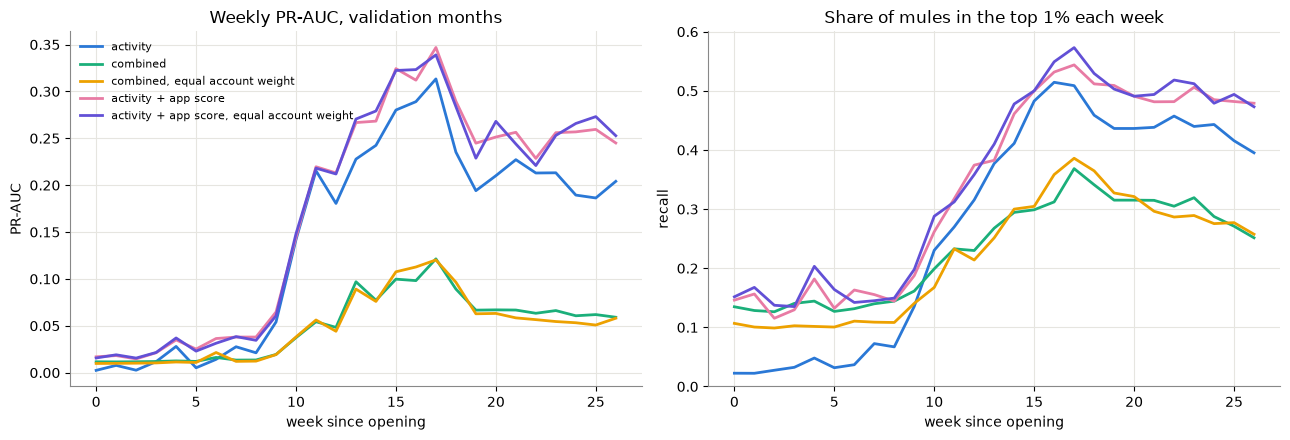

view,activity,combined,"combined, equal account weight",activity + app score,"activity + app score, equal account weight"
week,,,,,
0,0.002,0.012,0.010,0.017,0.016
4,0.028,0.013,0.011,0.035,0.037
8,0.021,0.014,0.012,0.038,0.034
10,0.142,0.037,0.038,0.144,0.148
12,0.181,0.048,0.044,0.213,0.212
16,0.289,0.098,0.113,0.312,0.323
20,0.210,0.067,0.063,0.251,0.268
26,0.204,0.059,0.058,0.245,0.253


In [5]:
COLORS = dict(zip(VARIANTS, ["#2a78d6", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]))   # validated categorical slots
wk = by_week(oof)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.edgecolor": "#888", "font.size": 10})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for name in VARIANTS:
    g = wk[wk["view"] == name].sort_values("week")
    axes[0].plot(g["week"], g["pr_auc"], color=COLORS[name], lw=2, label=name)
    axes[1].plot(g["week"], g["recall_top_1pct"], color=COLORS[name], lw=2, label=name)
axes[0].set(xlabel="week since opening", ylabel="PR-AUC", title="Weekly PR-AUC, validation months")
axes[1].set(xlabel="week since opening", ylabel="recall", title="Share of mules in the top 1% each week", ylim=(0, None))
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(REPORT / "01_by_week.png", dpi=130)
plt.show() if "ipykernel" in sys.modules else plt.close(fig)
wk_table = wk.pivot(index="week", columns="view", values="pr_auc")[list(VARIANTS)]
wk_table.loc[[0, 4, 8, 10, 12, 16, 20, 26]].round(3)

## 6. Conclusion and report

In [6]:
val, gap = summary["PR-AUC validation"], summary["gap"]
best = val.drop(APP_ONLY).idxmax()
lines = [
    f"- Best validation PR-AUC: **{best}**, {val[best]:.3f} (activity alone {val['activity']:.3f}, "
    f"combined baseline {val['combined']:.3f}).",
    f"- Memorising: training minus validation PR-AUC is {gap['combined']:.2f} for the combined baseline, "
    f"{gap['combined, equal account weight']:.2f} with equal account weight, {gap['activity + app score']:.2f} with the "
    f"application score and {gap['activity']:.2f} for activity alone.",
    f"- Idea 1 (equal account weight) moves combined from {val['combined']:.3f} to {val['combined, equal account weight']:.3f}; "
    f"idea 2 (application score) gives {val['activity + app score']:.3f}; both together "
    f"{val['activity + app score, equal account weight']:.3f}.",
    f"- Does the application add to activity? Activity + app score {val['activity + app score']:.3f} vs activity alone "
    f"{val['activity']:.3f}, in {int((by_fold.loc['activity + app score'] > by_fold.loc['activity']).sum())} of 3 folds higher.",
    f"- The application score alone reaches {val[APP_ONLY]:.3f} (logistic baseline on application columns: 0.025).",
]
BOTH = "activity + app score"
recall_wk = wk.pivot(index="week", columns="view", values="recall_top_1pct")
early = recall_wk.loc[0:8, [BOTH, "activity"]].mean()
weeks_better = int((wk_table[BOTH] > wk_table["activity"]).sum())
lines += [
    f"- Week by week, {BOTH} has the higher PR-AUC in {weeks_better} of {len(wk_table)} weeks. In weeks 0-8 it puts "
    f"{early[BOTH]:.0%} of the mules into each week's top 1%, activity alone {early['activity']:.0%}: the application "
    f"buys earliness, which the account-level measure (an account's best week out of 27) does not reward.",
    f"- Real-customer mules in the account-level top 1% (3 folds): activity alone {types.loc['activity', 'witting']} witting "
    f"and {types.loc['activity', 'unwitting']} unwitting; {BOTH} {types.loc[BOTH, 'witting']} and {types.loc[BOTH, 'unwitting']}. "
    f"The application score lifts fake accounts and pushes some real mules out of a fixed budget.",
]
print("\n".join(lines))

settings = {"data": OUT, "weeks": list(WEEKS), "folds": [f"{t} -> {v}" for t, v in FOLDS], "seed": SEED,
            "model": "LGBMClassifier, defaults, deterministic=True; class_weight='balanced' or equal account weights",
            "app_score": "LogisticRegression(class_weight='balanced', max_iter=2000) on accounts_linear, 5-fold out of fold",
            "app_score_label": "mule_by_day at week 26", "lightgbm": lgb.__version__}
res.to_csv(REPORT / "metrics_by_fold.csv", index=False)
wk.to_csv(REPORT / "oof_by_week.csv", index=False)
report = ["# LightGBM tuning, step 1: equal account weight and the application as one score", "",
          f"Settings: `{json.dumps(settings)}`", "", "## Conclusion", "", *lines, "",
          "## Account level, mean of 3 folds", "", summary.round(3).to_markdown(), "",
          "gap = training minus validation PR-AUC (large = memorised training accounts).", "",
          "## PR-AUC by fold", "", by_fold.round(3).to_markdown(), "",
          "## Mules in the top 1% by hidden type (caught / all, 3 folds summed)", "", types.to_markdown(), "",
          "## Weekly PR-AUC by week since opening", "", wk_table.loc[[0, 4, 8, 10, 12, 16, 20, 26]].round(3).to_markdown(), "",
          "![01_by_week.png](01_by_week.png)", ""]
(REPORT / "report.md").write_text("\n".join(report), encoding="utf-8")
print(f"saved to {REPORT} in {time.time() - T0:.0f}s")

- Best validation PR-AUC: **activity**, 0.730 (activity alone 0.730, combined baseline 0.256).
- Memorising: training minus validation PR-AUC is 0.74 for the combined baseline, 0.72 with equal account weight, 0.18 with the application score and 0.09 for activity alone.
- Idea 1 (equal account weight) moves combined from 0.256 to 0.279; idea 2 (application score) gives 0.695; both together 0.699.
- Does the application add to activity? Activity + app score 0.695 vs activity alone 0.730, in 1 of 3 folds higher.
- The application score alone reaches 0.022 (logistic baseline on application columns: 0.025).
- Week by week, activity + app score has the higher PR-AUC in 27 of 27 weeks. In weeks 0-8 it puts 15% of the mules into each week's top 1%, activity alone 4%: the application buys earliness, which the account-level measure (an account's best week out of 27) does not reward.
- Real-customer mules in the account-level top 1% (3 folds): activity alone 9/14 witting and 16/18 unwitting; acti